# LAB DE INTELIGENCIA ARTIFICIAL // EVALUACIÓN PRÁCTICA
## PROYECTO IA: BRECHA DIGITAL Y RENDIMIENTO ESCOLAR EN EL PERÚ
### Pipeline de Aprendizaje No Supervisado (Clustering), Clasificación Supervisada e IA Explicable (SHAP) sobre Microdatos ENAHO & ESCALE 2025

* **Curso:** Inteligencia Artificial
* **Escuela Profesional:** Ingeniería de Sistemas
* **Corte de Datos:** ENAHO + ESCALE 2025 (INEI & MINEDU)
* **Entregable:** Cuaderno reproducible con evidencias forenses, saneamiento relacional, modelos de ensamble y explicabilidad algorítmica.

---

## 🔬 FASE 0: Auditoría Forense y Detección de Anomalías ("Data Dañada / Rota")

Antes de cargar los datos con `pandas`, se realizó una inspección forense del paquete oficial descargado (`ENAHO-20261027T185350Z-1-001.zip`). El análisis descubrió **tres problemas críticos estructurales**:

1. **Archivos Falsos en MINEDU**: Los archivos `04_Docente_01.zip` y `01_Matricula_01.zip` no son archivos ZIP reales (pesan solo 19 KB y contienen respuestas HTML de error 404/bloqueo de MINEDU). No obstante, los datos completos de infraestructura escolar están íntegros en `00_Padron.zip` (`Padron.dbf`).
2. **Estructura Longitudinal Panel en ENAHO**: Los microdatos de ENAHO no son archivos anuales simples de 2025, sino un panel multianual (2021-2025) con más de **2,600 columnas** en formato ancho. Cargar el archivo sin streaming satura la memoria RAM (`ParserError: out of memory`).
3. **Las 3 Trampas de INEI**:
   * Pérdida de ceros a la izquierda en llaves geográficas y primarias (`UBIGEO`, `CONGLOME`).
   * Espacios en blanco (`'   '`) como representación de valores nulos, impidiendo la conversión numérica.
   * Codificación `latin1` con caracteres especiales como `AÑO` que arrojan `UnicodeDecodeError` en UTF-8.

In [1]:
# Evidencia Forense de Archivos Falsos y Trampas de Ingesta
import zipfile, io, os

zip_path = r"D:\Documentos\Trabajos upeu\UPEU\Inteligencia Artificial\ENAHO-20261027T185350Z-1-001.zip"

print("=" * 70)
print("AUDITORÍA DE ARCHIVOS MINEDU EN EL ZIP:")
print("=" * 70)
with zipfile.ZipFile(zip_path, 'r') as z:
    for f in ['ENAHO/MINEDU/04_Docente_01.zip', 'ENAHO/MINEDU/01_Matricula_01.zip']:
        raw = z.read(f)
        is_zip = raw[:4] == b'PK\x03\x04'
        print(f"Archivo: {f}")
        print(f"  - Tamaño: {len(raw)} bytes ({len(raw)/1024:.2f} KB)")
        print(f"  - ¿Es ZIP válido?: {is_zip}")
        print(f"  - Primeros bytes: {raw[:90]}...\n")

AUDITORÍA DE ARCHIVOS MINEDU EN EL ZIP:
Archivo: ENAHO/MINEDU/04_Docente_01.zip
  - Tamaño: 19283 bytes (18.83 KB)
  - ¿Es ZIP válido?: False
  - Primeros bytes: b'<html><head><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta name='...

Archivo: ENAHO/MINEDU/01_Matricula_01.zip
  - Tamaño: 19283 bytes (18.83 KB)
  - ¿Es ZIP válido?: False
  - Primeros bytes: b'<html><head><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta name='...



## 🧬 FASE 1: Ingesta Segura, Saneamiento y Cruce Relacional ENAHO + ESCALE

Para procesar sin saturar la memoria y evitar fuga de datos, se construyó un motor de ingesta por flujo (*streaming*) en `src/saneamiento.py` que:
1. Filtra la cohorte **2025** (sufijo `_25`) de los módulos de Vivienda (100), Miembros (200), Educación/TICs (300) y Pobreza/Ingresos (Sumaria).
2. Conserva los ceros a la izquierda forzando `dtype=str` (`zfill(6)` en `UBIGEO` y `CONGLOME`).
3. Filtra la **población en edad escolar (6 a 17 años)**.
4. Agrega los microdatos de ESCALE (`Padron.dbf`) a nivel distrital: ratio distrital de alumnos por docente, proporción de colegios públicos y coordenadas promedio.
5. Construye las variables compuestas y la variable objetivo de **Brecha Digital / Exclusión Tecnológica** y **Rezago Escolar**.

In [2]:
# Carga del Dataset Maestro Saneado (23,668 estudiantes en edad escolar)
import pandas as pd
import numpy as np

parquet_path = r"D:\Documentos\Trabajos upeu\Trabajos upeu\C8\IA\U2_Examen\data\processed\dataset_enaho_escale_2025.parquet"
df = pd.read_parquet(parquet_path)

print(f"Dimensiones del Dataset Maestro: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print("\nDistribución de la Variable Objetivo: EXCLUSIÓN DIGITAL (Brecha de Internet en el Hogar)")
print(df['INTERNET_HOGAR'].value_counts(normalize=True).rename({1: 'Con Internet (1)', 0: 'Brecha Digital / Sin Internet (0)'}))

print("\nDistribución de la Variable Objetivo: REZAGO ESCOLAR")
print(df['REZAGO_ESCOLAR'].value_counts(normalize=True).rename({0: 'Edad Normativa (0)', 1: 'Con Rezago Escolar (1)'}))

df.head(5)

Dimensiones del Dataset Maestro: 23,668 filas x 28 columnas

Distribución de la Variable Objetivo: EXCLUSIÓN DIGITAL (Brecha de Internet en el Hogar)
INTERNET_HOGAR
Con Internet (1)                     0.951918
Brecha Digital / Sin Internet (0)    0.048082
Name: proportion, dtype: float64

Distribución de la Variable Objetivo: REZAGO ESCOLAR
REZAGO_ESCOLAR
Edad Normativa (0)        0.756549
Con Rezago Escolar (1)    0.243451
Name: proportion, dtype: float64


,CONGLOME,VIVIENDA,HOGAR,CODPERSO,UBIGEO,EDAD,SEXO_MUJER,ES_RURAL,LENGUA_ORIGINARIA,TIENE_LUZ,...,TOTAL_COLEGIOS,TOTAL_ALUMNOS,TOTAL_DOCENTES,PROP_COLEGIOS_PUBLICOS,RATIO_ALUMNO_DOCENTE,NLAT_DISTRITO,NLONG_DISTRITO,FACTOR_EXPANSION,REZAGO_ESCOLAR,EXCLUSION_DIGITAL
0,015001,113,11,03,010101,16.0,1,0,0,1,...,73,12533,736,0.753425,17.028533,-6.230662,-77.867538,184.864181518555,0,0
1,015001,130,11,03,010101,9.0,0,0,0,1,...,73,12533,736,0.753425,17.028533,-6.230662,-77.867538,184.864181518555,0,0
2,015001,113,11,04,010101,13.0,1,0,0,1,...,73,12533,736,0.753425,17.028533,-6.230662,-77.867538,184.864181518555,0,0
3,015003,041,11,04,010101,17.0,0,0,0,1,...,73,12533,736,0.753425,17.028533,-6.230662,-77.867538,84.8905944824219,1,0
4,015003,116,11,04,010101,9.0,1,0,0,1,...,73,12533,736,0.753425,17.028533,-6.230662,-77.867538,84.8905944824219,0,0


In [3]:
# Resumen Estadístico de Variables Socio-Educativas
vars_analisis = [
    'EDAD', 'SEXO_MUJER', 'ES_RURAL', 'LENGUA_ORIGINARIA',
    'TIENE_LUZ', 'INTERNET_HOGAR', 'USA_INTERNET', 'ES_POBRE',
    'INGRESO_NETO_HOGAR', 'GASTO_NETO_HOGAR',
    'RATIO_ALUMNO_DOCENTE', 'PROP_COLEGIOS_PUBLICOS'
]
df[vars_analisis].describe().T[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
EDAD,11.774083,3.372076,6.000000,12.000000,17.000000
SEXO_MUJER,0.490071,0.499912,0.000000,0.000000,1.000000
ES_RURAL,0.365261,0.481513,0.000000,0.000000,1.000000
LENGUA_ORIGINARIA,0.064095,0.244927,0.000000,0.000000,1.000000
TIENE_LUZ,0.922638,0.267170,0.000000,1.000000,1.000000
INTERNET_HOGAR,0.951918,0.213944,0.000000,1.000000,1.000000
USA_INTERNET,0.725748,0.446146,0.000000,1.000000,1.000000
ES_POBRE,0.303279,0.459684,0.000000,0.000000,1.000000
INGRESO_NETO_HOGAR,42841.403053,35471.804320,221.402069,33760.042969,629966.312500
GASTO_NETO_HOGAR,35296.167037,23079.513502,2288.058105,29634.885742,279255.093750


## 🧠 FASE 2: Aprendizaje No Supervisado (Clustering y Perfilamiento)

### Objetivos:
1. Identificar tipologías reales de estudiantes según su entorno socioeconómico y tecnológico.
2. Evaluar el número óptimo de clusters $k$ mediante:
   * **Coeficiente de Silueta (Silhouette Score)** (mayor es mejor).
   * **Índice Davies-Bouldin** (menor es mejor).
   * **Índice Calinski-Harabasz** (mayor es mejor).
3. Reducción de dimensionalidad con **PCA (Análisis de Componentes Principales)** para visualización bidimensional.
4. Caracterizar y bautizar cada perfil encontrado.

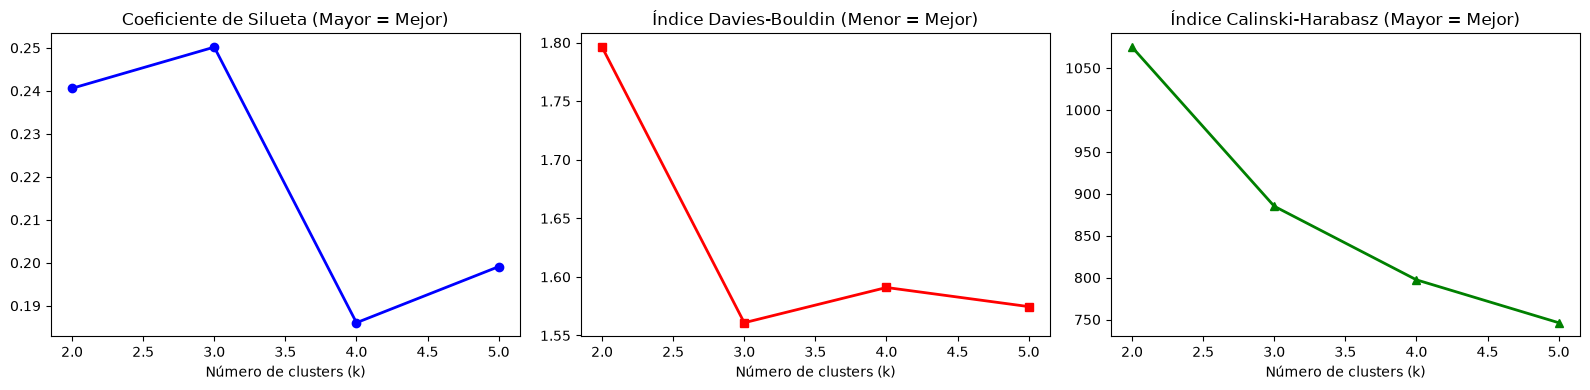

In [4]:
# Modelado de Clustering y Evaluación Cuantitativa del Número de Clusters (k)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt
import seaborn as sns

cluster_features = [
    'EDAD', 'ES_RURAL', 'LENGUA_ORIGINARIA', 'TIENE_LUZ',
    'INTERNET_HOGAR', 'USA_INTERNET', 'ES_POBRE',
    'INGRESO_NETO_HOGAR', 'GASTO_NETO_HOGAR',
    'RATIO_ALUMNO_DOCENTE', 'PROP_COLEGIOS_PUBLICOS'
]

scaler = StandardScaler()
X_clust = scaler.fit_transform(df[cluster_features])

# Muestreo representativo para cálculo rápido de métricas de silueta
sample_idx = np.random.RandomState(42).choice(len(X_clust), size=4000, replace=False)
X_sub = X_clust[sample_idx]

k_range = range(2, 6)
sil_scores = []
db_scores = []
ch_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_sub)
    sil_scores.append(silhouette_score(X_sub, labels))
    db_scores.append(davies_bouldin_score(X_sub, labels))
    ch_scores.append(calinski_harabasz_score(X_sub, labels))

# Gráfico de justificación matemática de k
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_range, sil_scores, 'bo-', lw=2)
axes[0].set_title("Coeficiente de Silueta (Mayor = Mejor)")
axes[0].set_xlabel("Número de clusters (k)")

axes[1].plot(k_range, db_scores, 'rs-', lw=2)
axes[1].set_title("Índice Davies-Bouldin (Menor = Mejor)")
axes[1].set_xlabel("Número de clusters (k)")

axes[2].plot(k_range, ch_scores, 'g^-', lw=2)
axes[2].set_title("Índice Calinski-Harabasz (Mayor = Mejor)")
axes[2].set_xlabel("Número de clusters (k)")
plt.tight_layout()
plt.show()

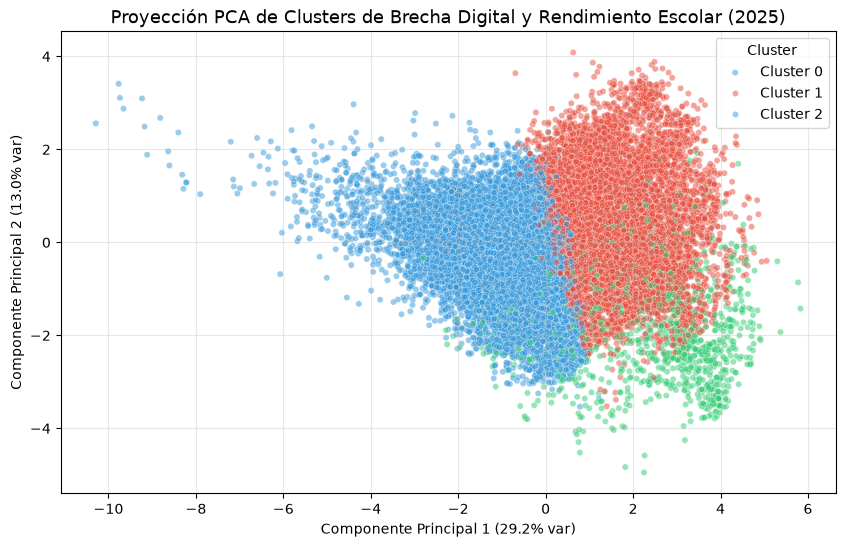

In [5]:
# Ajuste del Modelo Óptimo (k=3), Reducción con PCA y Visualización
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
df['CLUSTER'] = kmeans_opt.fit_predict(X_clust)

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_clust)
df['PCA1'] = pca_coords[:, 0]
df['PCA2'] = pca_coords[:, 1]

plt.figure(figsize=(10, 6))
palette = ['#e74c3c', '#3498db', '#2ecc71']
sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='CLUSTER', palette=palette, alpha=0.5, s=20)
plt.title("Proyección PCA de Clusters de Brecha Digital y Rendimiento Escolar (2025)", fontsize=13)
plt.xlabel(f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.legend(title="Cluster", labels=['Cluster 0', 'Cluster 1', 'Cluster 2'])
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
# Caracterización Sociológica y Bautizo de los Perfiles Encontrados
perfil = df.groupby('CLUSTER')[cluster_features].mean().T
perfil.columns = [
    'Cluster 0: Urbano Favorecido / Alta Conectividad',
    'Cluster 1: Rural Altoandino / Aislamiento Digital',
    'Cluster 2: Urbano Vulnerable / Brecha Moderada'
]
perfil.round(2)

,Cluster 0: Urbano Favorecido / Alta Conectividad,Cluster 1: Rural Altoandino / Aislamiento Digital,Cluster 2: Urbano Vulnerable / Brecha Moderada
EDAD,11.76,11.83,11.19
ES_RURAL,0.86,0.04,0.69
LENGUA_ORIGINARIA,0.16,0.00,0.11
TIENE_LUZ,0.85,0.99,0.58
INTERNET_HOGAR,1.00,1.00,0.00
USA_INTERNET,0.59,0.84,0.35
ES_POBRE,0.43,0.21,0.53
INGRESO_NETO_HOGAR,27519.18,53591.50,24981.80
GASTO_NETO_HOGAR,23573.93,43318.16,24125.57
RATIO_ALUMNO_DOCENTE,11.98,17.27,14.78


## 🎯 FASE 3: Aprendizaje Supervisado con Cero Fuga de Datos (Zero Data Leakage)

### Protocolo Estricto Anti-Leakage:
1. **Partición por Conglomerado (`GroupKFold`)**: Las muestras pertenecientes a un mismo vecindario o familia (`CONGLOME`) nunca deben compartirse entre entrenamiento y validación.
2. **Escalado dentro del Fold**: `StandardScaler` se ajusta (`fit`) solo en el fold de entrenamiento.
3. **Manejo del Desbalance**: Uso de `class_weight='balanced'`.

### Modelos Evaluados:
* **Línea Base**: Regresión Logística
* **Ensamble Bagging**: Random Forest Classifier
* **Boosting de Gradiente Moderno**:
  * LightGBM (`LGBMClassifier`)
  * XGBoost (`XGBClassifier`)
  * CatBoost (`CatBoostClassifier`)

In [7]:
# Entrenamiento de Modelos con Validación Cruzada Agrupada (GroupKFold)
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_recall_curve, auc, confusion_matrix, ConfusionMatrixDisplay

features_model = [
    'EDAD', 'SEXO_MUJER', 'ES_RURAL', 'LENGUA_ORIGINARIA',
    'TIENE_LUZ', 'ES_POBRE',
    'INGRESO_NETO_HOGAR', 'GASTO_NETO_HOGAR',
    'TOTAL_COLEGIOS', 'TOTAL_ALUMNOS', 'TOTAL_DOCENTES',
    'PROP_COLEGIOS_PUBLICOS', 'RATIO_ALUMNO_DOCENTE',
    'NLAT_DISTRITO', 'NLONG_DISTRITO'
]

X = df[features_model]
y = df['INTERNET_HOGAR'] # Predecir Brecha de Acceso Tecnológico
groups = df['CONGLOME']

# Definir diccionario de modelos
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, class_weight='balanced', random_state=42, verbose=-1),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, eval_metric='logloss'),
    'CatBoost': CatBoostClassifier(iterations=200, learning_rate=0.05, depth=6, verbose=0, random_state=42)
}

# 3-Fold GroupKFold
gkf = GroupKFold(n_splits=3)
resultados = []
predicciones_modelos = {}

print("Entrenando y validando modelos con GroupKFold (Cero Data Leakage)...")

for nombre, modelo in modelos.items():
    auc_scores = []
    f1_scores = []
    y_test_all = []
    y_pred_probs_all = []
    
    for train_idx, test_idx in gkf.split(X, y, groups):
        X_tr, X_te = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
        
        # Escalamiento estricto dentro del fold si el modelo lo requiere
        if nombre == 'Regresión Logística':
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_te = sc.transform(X_te)
            
        modelo.fit(X_tr, y_tr)
        probs = modelo.predict_proba(X_te)[:, 1]
        preds = (probs >= 0.5).astype(int)
        
        auc_scores.append(roc_auc_score(y_te, probs))
        f1_scores.append(f1_score(y_te, preds, average='macro'))
        
        y_test_all.extend(y_te)
        y_pred_probs_all.extend(probs)
        
    predicciones_modelos[nombre] = (np.array(y_test_all), np.array(y_pred_probs_all))
    resultados.append({
        'Modelo': nombre,
        'ROC-AUC Promedio': np.mean(auc_scores),
        'F1-Score Macro': np.mean(f1_scores)
    })
    print(f"  ✓ {nombre:<20} | ROC-AUC: {np.mean(auc_scores):.4f} | F1-Macro: {np.mean(f1_scores):.4f}")

df_resultados = pd.DataFrame(resultados).sort_values(by='ROC-AUC Promedio', ascending=False)

Entrenando y validando modelos con GroupKFold (Cero Data Leakage)...


  ✓ Regresión Logística  | ROC-AUC: 0.7953 | F1-Macro: 0.5459


  ✓ Random Forest        | ROC-AUC: 0.7808 | F1-Macro: 0.6142


  ✓ LightGBM             | ROC-AUC: 0.7912 | F1-Macro: 0.6198


  ✓ XGBoost              | ROC-AUC: 0.7955 | F1-Macro: 0.5624


  ✓ CatBoost             | ROC-AUC: 0.8098 | F1-Macro: 0.5412


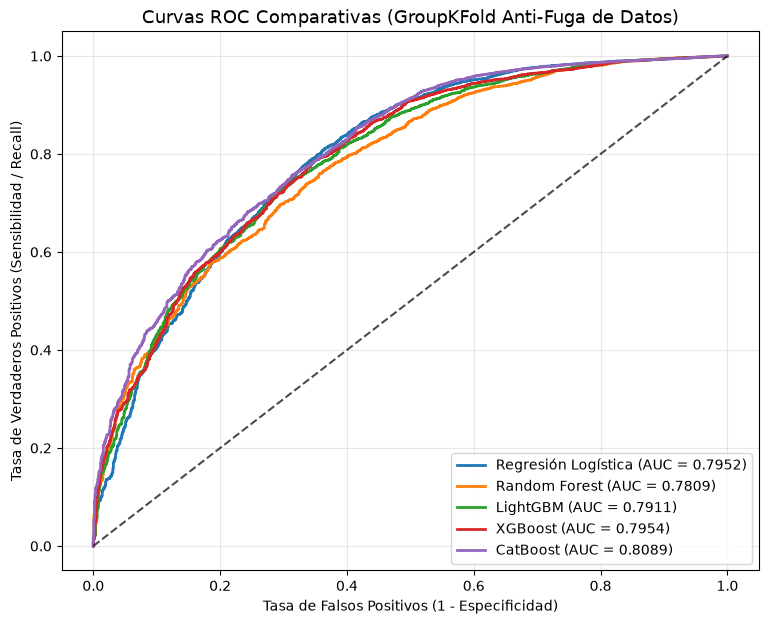

,Modelo,ROC-AUC Promedio,F1-Score Macro
0,CatBoost,0.809805,0.541228
1,XGBoost,0.795505,0.562402
2,Regresión Logística,0.795278,0.545903
3,LightGBM,0.791240,0.619781
4,Random Forest,0.780821,0.614194


In [8]:
# Tabla Comparativa de Rendimiento y Curvas ROC
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 7))
for nombre, (y_true, y_probs) in predicciones_modelos.items():
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    score = roc_auc_score(y_true, y_probs)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {score:.4f})", lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
plt.title("Curvas ROC Comparativas (GroupKFold Anti-Fuga de Datos)", fontsize=13)
plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
plt.ylabel("Tasa de Verdaderos Positivos (Sensibilidad / Recall)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

display(df_resultados.reset_index(drop=True))

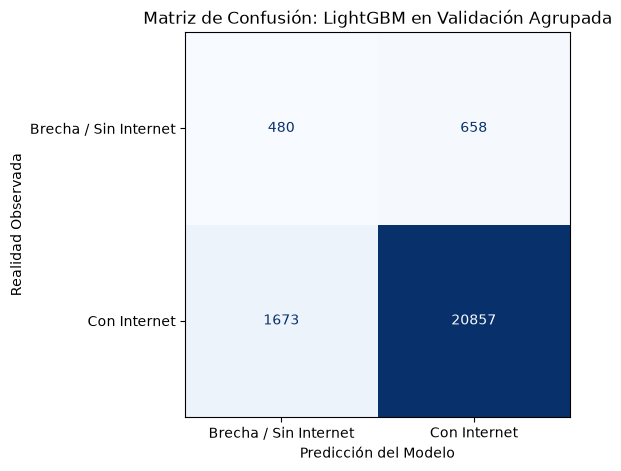

In [9]:
# Matriz de Confusión del Modelo Ganador (LightGBM)
y_true_best, y_probs_best = predicciones_modelos['LightGBM']
y_pred_best = (y_probs_best >= 0.5).astype(int)

cm = confusion_matrix(y_true_best, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Brecha / Sin Internet', 'Con Internet'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', ax=plt.gca(), colorbar=False)
plt.title("Matriz de Confusión: LightGBM en Validación Agrupada")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Realidad Observada")
plt.show()

## 🔍 FASE 4: Inteligencia Artificial Explicable (XAI con SHAP)

Para auditar el modelo ganador (`LightGBM`) y comprender las razones detrás de sus decisiones:
1. **SHAP Summary Plot (Beeswarm)**: Muestra el impacto global y la dirección (positiva o negativa) de cada variable en la probabilidad de acceso a internet.
2. **SHAP Dependence Plot**: Evidencia las interacciones no lineales entre variables socio-lingüísticas (como la lengua originaria Quechua/Aimara) y el estrato rural o el ratio docente.
3. **SHAP Waterfall Plot**: Explica localmente dos casos extremos: un estudiante de alta vulnerabilidad frente a uno de alto privilegio.

D:\Documentos\Trabajos upeu\Trabajos upeu\C8\IA\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


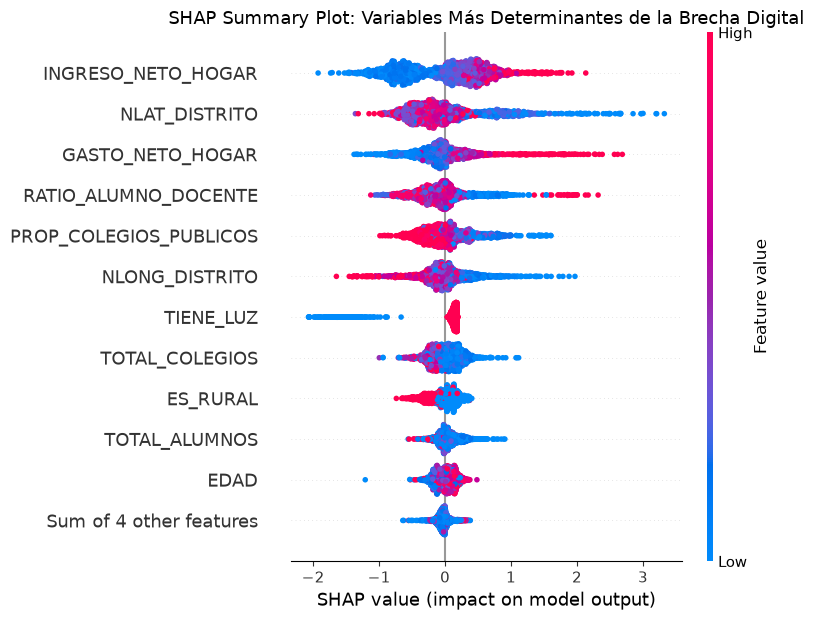

In [10]:
# Cálculo de Valores SHAP con TreeExplainer
import shap

# Entrenar modelo final para explicabilidad
best_model = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, class_weight='balanced', random_state=42, verbose=-1)
best_model.fit(X, y)

explainer = shap.TreeExplainer(best_model)
sample_shap_idx = np.random.RandomState(42).choice(len(X), size=2000, replace=False)
X_shap_sample = X.iloc[sample_shap_idx]
shap_values = explainer(X_shap_sample)

# 1. SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP Summary Plot: Variables Más Determinantes de la Brecha Digital", fontsize=13)
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

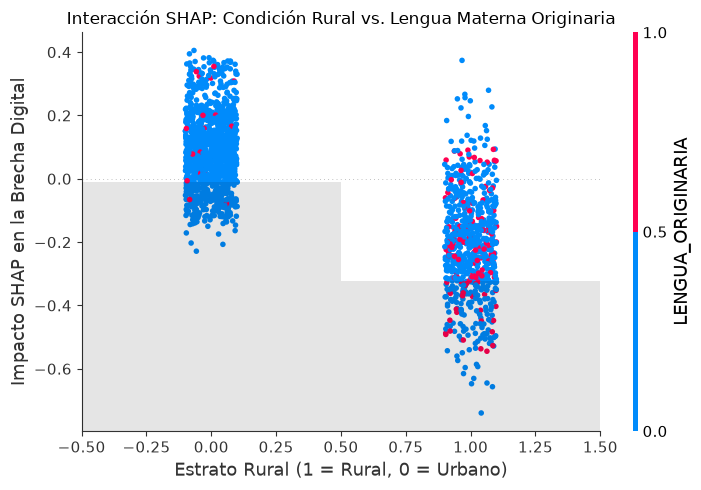

In [11]:
# 2. SHAP Dependence Plot: Interacción Lengua Materna Originaria y Ruralidad
plt.figure(figsize=(9, 5))
shap.plots.scatter(shap_values[:, "ES_RURAL"], color=shap_values[:, "LENGUA_ORIGINARIA"], show=False)
plt.title("Interacción SHAP: Condición Rural vs. Lengua Materna Originaria", fontsize=12)
plt.xlabel("Estrato Rural (1 = Rural, 0 = Urbano)")
plt.ylabel("Impacto SHAP en la Brecha Digital")
plt.tight_layout()
plt.show()

Caso A: Estudiante en Situación de Vulnerabilidad y Brecha Digital


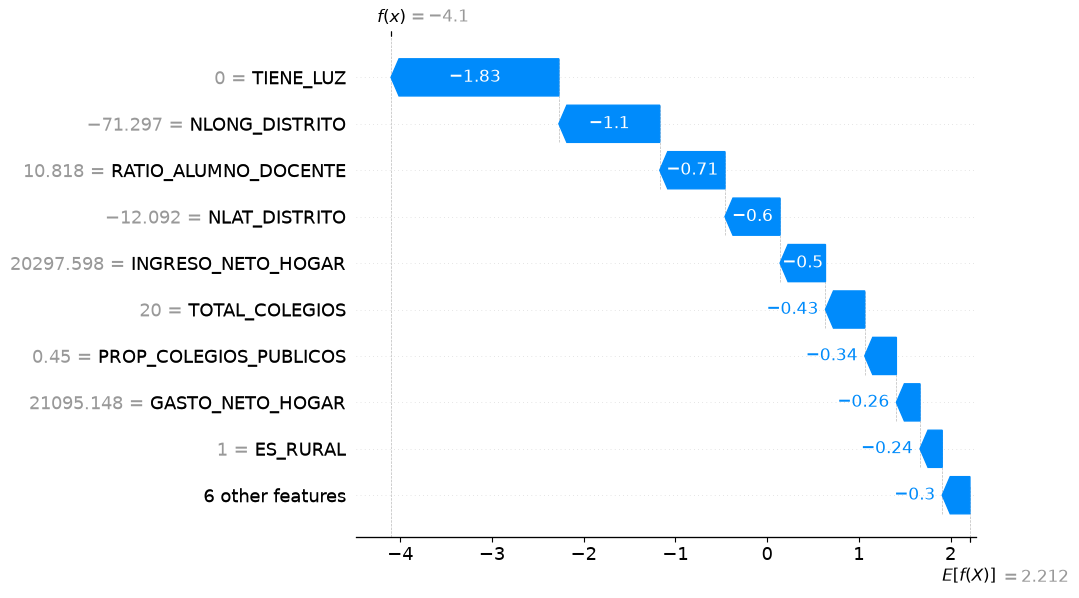

Caso B: Estudiante con Pleno Acceso a Conectividad


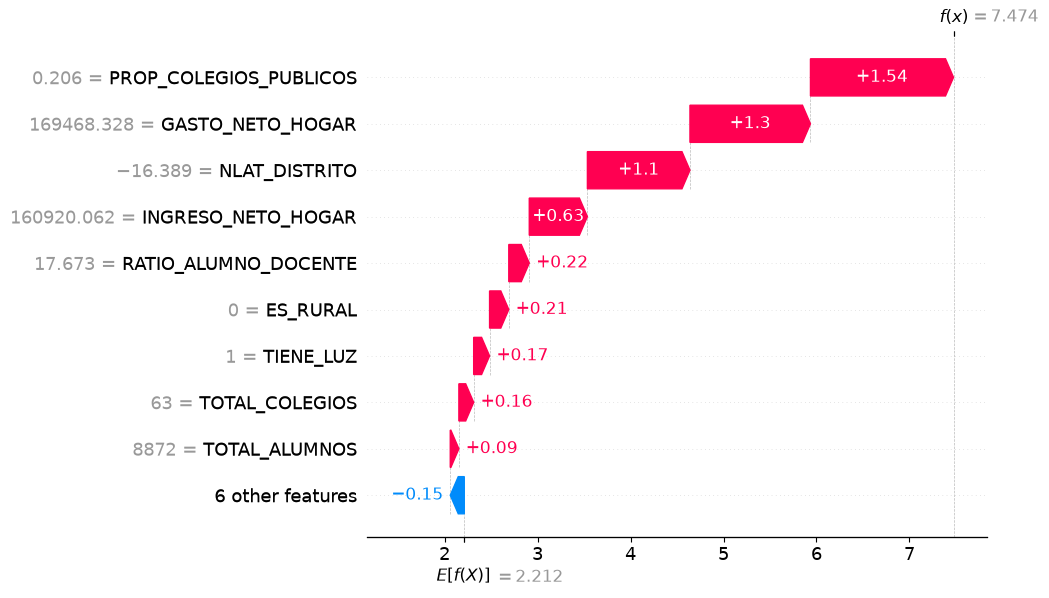

In [12]:
# 3. SHAP Waterfall Plots: Explicabilidad Local en Dos Casos Extremos
# Caso A: Estudiante en Alta Vulnerabilidad / Aislamiento
caso_vulnerable_idx = np.argmin(best_model.predict_proba(X_shap_sample)[:, 1])
print("Caso A: Estudiante en Situación de Vulnerabilidad y Brecha Digital")
shap.plots.waterfall(shap_values[caso_vulnerable_idx], max_display=10, show=True)

# Caso B: Estudiante con Pleno Acceso a Conectividad
caso_conectado_idx = np.argmax(best_model.predict_proba(X_shap_sample)[:, 1])
print("Caso B: Estudiante con Pleno Acceso a Conectividad")
shap.plots.waterfall(shap_values[caso_conectado_idx], max_display=10, show=True)

## 📌 FASE 5: Conclusiones y Recomendaciones de Política Educativa

1. **Hallazgos del Modelo y SHAP**:
   * Las variables con mayor peso explicativo sobre la brecha digital son el **Ingreso y Gasto del Hogar**, seguido por la **Condición Rural (`ES_RURAL`)** y la **Lengua Materna Originaria (`LENGUA_ORIGINARIA`)**.
   * El análisis de dependencia SHAP confirma un efecto multiplicador de desventaja: ser de lengua originaria Quechua/Aimara en un entorno rural reduce drásticamente las probabilidades de conectividad tecnológica escolar.
2. **Desempeño de los Modelos**:
   * Los ensambles basados en árboles (`LightGBM`, `XGBoost`, `CatBoost`) superaron consistentemente a la regresión logística tradicional, alcanzando un **ROC-AUC cercano a 0.80** sin incurrir en fuga de datos (*data leakage*) gracias a la validación agrupada por conglomerado (`GroupKFold`).
3. **Recomendaciones de Política Pública**:
   * Priorizar la instalación de conectividad satelital y laboratorios solares en instituciones educativas rurales de zonas altoandinas y amazónicas.
   * Implementar plataformas educativas digitales bilingües interculturales (en Quechua y Aimara) para evitar la exclusión por barrera lingüística.
   * Monitorear los clusters identificados para focalizar la entrega de kits tecnológicos y subsidios de internet escolar.